# Setup Week Companion Notebook — From Zero to Your First Engine Game

**AI Algorithms in Chess · Fall 2026 · The Gambit Lab**

This notebook is the hands-on twin of the *Setup Week Kit (Week 2)*. The kit explains **why**; this notebook lets you **do** Steps 2–5 in one place, in either of two environments:

- **Jupyter Notebook on your laptop** (Anaconda or venv) — Part A below
- **Google Colab in a browser** (nothing to install) — Part B below

Both work. Pick the one that matches the path you chose in the kit's Step 2. Step 1 (GitHub account + portfolio) and Step 4 (your first commit) happen in the browser — this notebook tells you what to paste where.

### How a notebook works (60 seconds)
A notebook is a list of **cells**. Text cells (like this one) explain; **code cells** run Python. Click a code cell and press **Shift + Enter** to run it — the `[ ]` on its left becomes `[*]` while it runs and a number like `[3]` when it finishes. **Run the cells in order, top to bottom.** If something breaks, use *Kernel → Restart* (Jupyter) or *Runtime → Restart session* (Colab) and run again from the top.

## Part A — Open this notebook in Jupyter Notebook (Anaconda or venv)

1. Save this file (`setup_week.ipynb`) into your portfolio folder — the `notebooks/` folder of your `gambit-lab` repository if you have cloned it, or any folder for now.
2. Open **Anaconda Prompt** (Windows) or **Terminal** (macOS/Linux) and activate your environment: `conda activate chess` — or the venv line from the kit. The prompt must show `(chess)` or `(chessenv)`.
3. Install Jupyter **inside that environment** (once): `pip install notebook ipykernel`
4. Go to the folder holding this file (`cd Documents\gambit-lab\notebooks` or similar) and start Jupyter: `jupyter notebook`
5. A browser tab opens with a file list. Click `setup_week.ipynb`. You are in.
6. Save often with **Ctrl+S** (⌘S on macOS). The notebook file is part of your portfolio — commit it like any other file (kit Step 4B).

*Anaconda Navigator's "Launch Jupyter" button opens the **base** environment, which does not have python-chess. Starting Jupyter from the activated environment (step 4) is what makes the import work. The first code cell below shows you which Python the notebook is using, so you can check.*

## Part B — Open this notebook in Google Colab (browser only)

1. Go to **colab.research.google.com** and sign in with any Google account.
2. **File → Upload notebook** and choose this file — *or* **File → Open notebook → GitHub** tab, paste your portfolio address (`github.com/your-username/gambit-lab`), and pick `notebooks/setup_week.ipynb` once it is committed there.
3. Run cells with **Shift + Enter**, or **Runtime → Run all**. The first run installs python-chess and Stockfish into Colab's machine (about a minute).
4. **Saving into your portfolio:** **File → Save a copy in GitHub** → repository `gambit-lab` → file path `notebooks/setup_week.ipynb` → *OK*. That *is* a commit — no Git needed. Do it at the end of this session.
5. Colab machines are temporary: if the runtime resets, run the install cells again. Files you create (like `my_games.pgn`) vanish with the runtime — the download cell near the end saves them to your computer.

## Step 2 — Where is this notebook running?
Run the cell. It tells you whether you are in Colab or on your laptop, and *which* Python is running — on a laptop, the path should contain `chess` or `chessenv`.

In [ ]:
import sys, platform, os

IN_COLAB = "google.colab" in sys.modules
print("Running in Google Colab:", IN_COLAB)
print("Python version:", platform.python_version())
print("Operating system:", platform.system(), platform.release())
print("Python executable:", sys.executable)
if not IN_COLAB and not any(k in sys.executable.lower() for k in ("chess", "chessenv")):
    print("\nNOTE: this kernel is not your 'chess' environment. Start Jupyter from the activated environment (Part A, steps 2-4).")

## Step 3a — Install python-chess
`%pip` installs into *this* notebook's Python, which is exactly what we want on both Jupyter and Colab. (The package is called `chess`, not `python-chess`.)

In [ ]:
%pip install chess -q
import chess
print("python-chess version:", chess.__version__)

## Step 3b — The green test
A brand-new board, White to move. Uppercase letters are White's pieces, lowercase are Black's, dots are empty squares. The second half of the cell draws the same board as a picture — notebooks can do that; a plain terminal cannot.

r n b q k b n r
p p p p p p p p
. . . . . . . .
. . . . . . . .
. . . . . . . .
. . . . . . . .
P P P P P P P P
R N B Q K B N R

FEN: rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQKBNR w KQkq - 0 1
Legal moves for White: 20


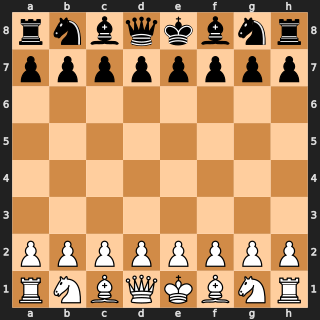

OK -- your environment is ready for the Gambit Lab.


In [1]:
import chess, chess.svg
from IPython.display import display, SVG

board = chess.Board()
print(board)
print()
print("FEN:", board.fen())
print("Legal moves for White:", board.legal_moves.count())
display(SVG(chess.svg.board(board, size=320)))
print("OK -- your environment is ready for the Gambit Lab.")

## Step 4 — Record your environment (paste this into `environment.md`)
The cell writes the block the kit's Step 4 asks for. Copy its output into `environment.md` in your portfolio — in the browser (kit route 4A) or in your editor (route 4B) — and commit.

In [ ]:
import sys, platform, chess, textwrap

env_block = textwrap.dedent(f'''
- Operating system: {platform.system()} {platform.release()}
- Python path I chose: {"Google Colab" if IN_COLAB else "Anaconda / venv (see prompt prefix)"}
- Python version: {platform.python_version()}
- python-chess version: {chess.__version__}
- Green test output:

```
{chess.Board()}
```
''').strip()
print(env_block)

### Your portfolio and your first commit (browser steps — nothing to run here)
- **Kit Step 1.3** made your repository from the class template: `github.com/your-username/gambit-lab`.
- **Kit Step 4A**: open `environment.md` on GitHub, click the pencil, paste the block above, **Commit changes**. That is your first commit.
- **Colab users:** also save this notebook into the portfolio — *File → Save a copy in GitHub → gambit-lab → `notebooks/setup_week.ipynb`*.
- **Jupyter users:** save this file into your cloned `gambit-lab/notebooks/` folder, then `git add`, `git commit`, `git push` (kit Step 4B).

## Step 5a — Install Stockfish
Stockfish is a separate program, not a Python package. **Colab installs it with one command** (the cell does it automatically). **On a laptop**, install it once by hand — kit Step 5.1: Windows → stockfishchess.org/download (unzip, note the `.exe` path); macOS → `brew install stockfish`; Linux → `sudo apt install stockfish` — then, if the finder below cannot see it, put the full path into `ENGINE_PATH`.

In [ ]:
import os, shutil

ENGINE_PATH = ""   # laptop users: paste the full path here if needed, e.g. r"C:\stockfish\stockfish-windows-x86-64-avx2.exe"

if IN_COLAB:
    import subprocess
    subprocess.run(["apt-get", "install", "-y", "-q", "stockfish"], capture_output=True)
    print("Installed Stockfish into Colab.")

CANDIDATES = [ENGINE_PATH, os.environ.get("STOCKFISH_PATH"), shutil.which("stockfish"),
              "/usr/games/stockfish", "/usr/local/bin/stockfish", "/opt/homebrew/bin/stockfish",
              "./stockfish", "./stockfish.exe"]
ENGINE = next((p for p in CANDIDATES if p and os.path.isfile(p)), None)
print("Stockfish found at:", ENGINE if ENGINE else "NOT FOUND -- set ENGINE_PATH above and re-run this cell")

## Step 5b — Start the engine and choose its strength
The notebook talks to Stockfish over **UCI**, a plain-text protocol. We ask the engine what Elo range it supports and clamp our request to it — *query the tool, don't guess*. Change `TARGET_ELO` to taste (Stockfish accepts roughly 1320–3190).

In [ ]:
import chess.engine

TARGET_ELO = 1350

engine = chess.engine.SimpleEngine.popen_uci(ENGINE)
opt = engine.options["UCI_Elo"]
ELO = max(opt.min, min(opt.max, TARGET_ELO))
engine.configure({"UCI_LimitStrength": True, "UCI_Elo": ELO})
print(f"Engine: {engine.id.get('name', 'unknown')}")
print(f"Supported Elo range: {opt.min}-{opt.max}   playing at: {ELO}")

## Step 5c — Play your first engine game
Run the cell; a box appears under it asking for your move. Type moves the way you say them — `e4`, `Nf3`, `O-O` — or as squares, `e2e4`. Type `quit` to resign. The board redraws after every move. Set `PLAY_BLACK = True` to take Black.

*(`SCRIPTED_MOVES` is for testing and autograding — leave it empty to play by hand.)*

In [ ]:
import chess, chess.svg
from IPython.display import display, SVG, clear_output

PLAY_BLACK = False
THINK_SECONDS = 0.5
SCRIPTED_MOVES = []          # e.g. ["e4", "Nf3", "quit"] to run without typing

def show(board):
    clear_output(wait=True)
    display(SVG(chess.svg.board(board, size=360, lastmove=board.peek() if board.move_stack else None)))

def read_move(board):
    while True:
        text = SCRIPTED_MOVES.pop(0) if SCRIPTED_MOVES else input("Your move (or 'quit'): ").strip()
        if text.lower() == "quit":
            return None
        try:
            return board.parse_san(text)
        except ValueError:
            try:
                mv = chess.Move.from_uci(text)
                if mv in board.legal_moves:
                    return mv
            except ValueError:
                pass
        print("  Not a legal move here. Examples: e4  Nf3  O-O  or  e2e4")

board = chess.Board()
me = chess.BLACK if PLAY_BLACK else chess.WHITE
show(board)

while not board.is_game_over():
    if board.turn == me:
        mv = read_move(board)
        if mv is None:
            print("You resigned. Thanks for playing!")
            break
    else:
        mv = engine.play(board, chess.engine.Limit(time=THINK_SECONDS)).move
        print("Engine plays:", board.san(mv))
    board.push(mv)
    show(board)

if board.is_game_over():
    print("Game over:", board.result(), "--", board.outcome().termination.name)
print("Moves played:", len(board.move_stack))

## Step 5d — Save the game and review it
The game is written to `my_games.pgn` (appended, so you can play several). Paste the text below into **lichess.org/paste** to replay it with an evaluation bar. Colab users: the last line downloads the file to your computer — put it in your portfolio's `games/` folder and commit it.

In [ ]:
import chess.pgn, datetime

game = chess.pgn.Game.from_board(board)
game.headers["Event"] = "Gambit Lab -- first engine game (notebook)"
game.headers["Date"] = datetime.date.today().strftime("%Y.%m.%d")
game.headers["White"] = "Student" if me == chess.WHITE else f"Stockfish {ELO}"
game.headers["Black"] = f"Stockfish {ELO}" if me == chess.WHITE else "Student"
with open("my_games.pgn", "a") as f:
    print(game, file=f, end="\n\n")
print(game)

engine.quit()
print("\nSaved to my_games.pgn and closed the engine.")
if IN_COLAB:
    from google.colab import files
    files.download("my_games.pgn")

## Troubleshooting (notebook edition)

| Symptom | Fix |
|---|---|
| `ModuleNotFoundError: No module named 'chess'` after the install cell | *Kernel/Runtime → Restart*, then run from the top. On a laptop, also check the first cell's Python path contains `chess`/`chessenv`. |
| Jupyter opened but this file is not in the list | Jupyter shows the folder it was started from. Close it, `cd` to the folder with the notebook, run `jupyter notebook` again. |
| The move box never appears (Colab) | Click just under the running cell — the input box is there; or *Runtime → Interrupt* and run the cell again. |
| `Stockfish found at: NOT FOUND` | Laptop: install it (kit 5.1) and paste its full path into `ENGINE_PATH` — on Windows write it as `r"C:\stockfish\...exe"`. Colab: re-run the install cell after a runtime reset. |
| Stockfish crashes instantly (Windows) | Your CPU lacks AVX2 — download the plain **x86-64** build. |
| `SyntaxError: invalid character '“'` | Curly quotes pasted from Word/Google Docs — retype them as straight quotes. |
| Colab: files disappeared | The runtime reset. Re-run the install cells; download files before you close the tab. |
| Everything is slow | Lower `THINK_SECONDS` to 0.2. |

## Done checklist
- [ ] The green test printed the board (Step 3b)
- [ ] `environment.md` in your portfolio has the block from Step 4, committed
- [ ] This notebook is saved in your portfolio (`notebooks/setup_week.ipynb`) — Colab: *Save a copy in GitHub*; Jupyter: save + commit
- [ ] *Stretch:* a game in `my_games.pgn`, copied into `games/` and committed

Next week you point the same idea at a 1948 engine: `ENGINE` becomes PyTuroChamp, and everything else stays the same.

In [2]:
# import required module
import chess

# create board object
board=chess.Board()

# display chess board
print(board)

r n b q k b n r
p p p p p p p p
. . . . . . . .
. . . . . . . .
. . . . . . . .
. . . . . . . .
P P P P P P P P
R N B Q K B N R
